In [100]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [101]:
import pandas as pd

In [102]:
path="/content/drive/MyDrive/Dataset/telco_customer_churn.csv"

In [103]:
df=pd.read_csv(path)
df.head(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [104]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [105]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [106]:
df2=df.copy()
df2.head(3)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


In [107]:
df2.drop("customerID",axis=1,inplace=True)


In [108]:
df2.dtypes

,0
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object
OnlineBackup,object


In [109]:
df2.TotalCharges=pd.to_numeric(df2.TotalCharges,errors='coerce')
median_val = df2['TotalCharges'].median()
df2['TotalCharges'].fillna(median_val, inplace=True)
df2.SeniorCitizen=df2.SeniorCitizen.astype(str)
df2.dtypes

/tmp/ipython-input-4149866020.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df2['TotalCharges'].fillna(median_val, inplace=True)


,0
gender,object
SeniorCitizen,object
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object
OnlineBackup,object


In [110]:
df2.head(4)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No


In [111]:
numerical_data = df2.select_dtypes(include='number')
numerical_features=numerical_data.columns.tolist()
print(f'There are {len(numerical_features)} numerical features:', '\n')
print(numerical_features)

There are 3 numerical features: 

['tenure', 'MonthlyCharges', 'TotalCharges']


In [112]:
categorical_data = df2.select_dtypes(include='object')
categroical_features=categorical_data.columns.tolist()
print(f'There are {len(categroical_features)} categorical features:', '\n')
print(categroical_features)

There are 17 categorical features: 

['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']


In [113]:
numerical_data.skew()

,0
tenure,0.239540
MonthlyCharges,-0.220524
TotalCharges,0.963789


Here TotalCharges is moderately right skewed.

In [114]:
for col in categroical_features:
  print(df2[col].value_counts(normalize=True),"\n")

gender
Male      0.504756
Female    0.495244
Name: proportion, dtype: float64 

SeniorCitizen
0    0.837853
1    0.162147
Name: proportion, dtype: float64 

Partner
No     0.516967
Yes    0.483033
Name: proportion, dtype: float64 

Dependents
No     0.700412
Yes    0.299588
Name: proportion, dtype: float64 

PhoneService
Yes    0.903166
No     0.096834
Name: proportion, dtype: float64 

MultipleLines
No                  0.481329
Yes                 0.421837
No phone service    0.096834
Name: proportion, dtype: float64 

InternetService
Fiber optic    0.439585
DSL            0.343746
No             0.216669
Name: proportion, dtype: float64 

OnlineSecurity
No                     0.496663
Yes                    0.286668
No internet service    0.216669
Name: proportion, dtype: float64 

OnlineBackup
No                     0.438450
Yes                    0.344881
No internet service    0.216669
Name: proportion, dtype: float64 

DeviceProtection
No                     0.439443
Yes         

In [115]:
x=df2.iloc[:, :-1]
y=df2.iloc[:, -1]

label_encode=[]
dummy_encode=["Contract","PaymentMethod"]
for i in categroical_features:
  if i in dummy_encode:
    continue
  label_encode.append(i)
print(label_encode)



['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling', 'Churn']


In [116]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(x,y, test_size = 0.30,stratify=y, random_state=0)

X_train_encoded = pd.get_dummies(X_train[dummy_encode])
X_test_encoded = pd.get_dummies(X_test[dummy_encode])


X_train = X_train.drop(columns=dummy_encode)
X_test = X_test.drop(columns=dummy_encode)


X_train_processed = X_train.join(X_train_encoded)
X_test_processed = X_test.join(X_test_encoded)

dummy=X_train_encoded.columns.to_list()
label_encode.extend(dummy)
print(label_encode)


['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling', 'Churn', 'Contract_Month-to-month', 'Contract_One year', 'Contract_Two year', 'PaymentMethod_Bank transfer (automatic)', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']


In [117]:
from sklearn.preprocessing import LabelEncoder
X_train_le = X_train_processed.copy()
X_test_le = X_test_processed.copy()
for col in label_encode:
  label=LabelEncoder()
  if col != "Churn":

    X_train_le[col]=label.fit_transform(X_train_processed[col])
    X_test_le[col]=label.transform(X_test_processed[col])

  else:
    y_train_le=pd.DataFrame(label.fit_transform(y_train),columns=[col])
    y_test_le=pd.DataFrame(label.transform(y_test),columns=[col])



In [118]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

# Fit on train and transform
X_train_le[['TotalCharges']] = scaler.fit_transform(X_train_le[['TotalCharges']])

# Only transform test
X_test_le[['TotalCharges']] = scaler.transform(X_test_le[['TotalCharges']])


In [119]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier

# Define models
models = {
    "Logistic Regression": LogisticRegression(max_iter=5000,random_state=42),
    "Decison Tree": DecisionTreeClassifier(
          max_depth=5,
          min_samples_leaf=10,
          random_state=42
          ),
    "Neural Network":MLPClassifier(
          hidden_layer_sizes=(30, 30),
          activation='relu',
          solver='adam',
          learning_rate_init=0.001,
          max_iter=500,
          random_state=42

    )
}


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:1124: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


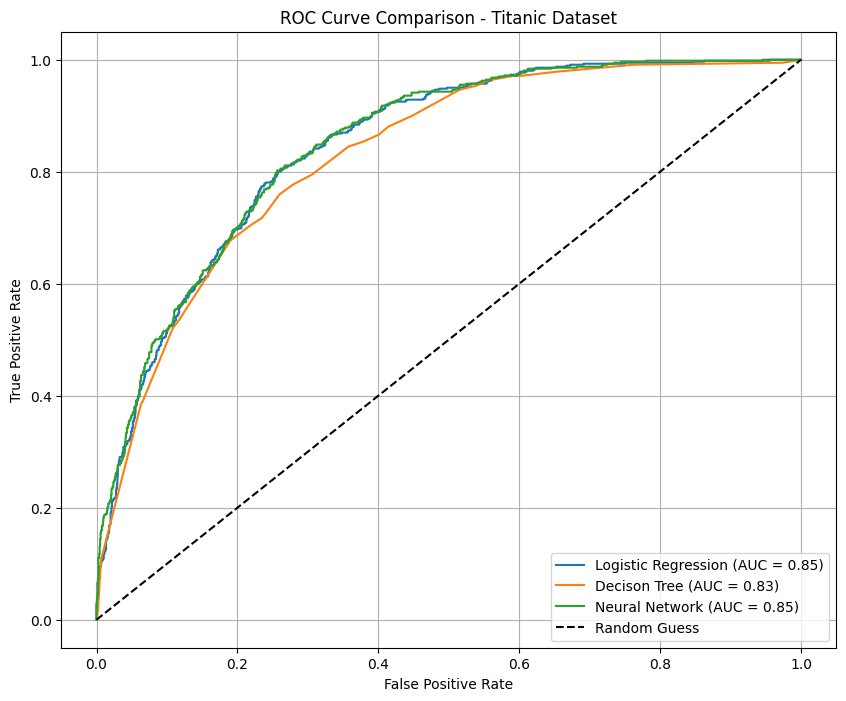

In [120]:

from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt


plt.figure(figsize=(10, 8))

for name, model in models.items():
    # Fit
    model.fit(X_train_le, y_train_le)

    # Predict probabilities for class 1 (survived)
    y_probs = model.predict_proba(X_test_le)[:, 1]

    # ROC and AUC
    fpr, tpr, _ = roc_curve(y_test_le, y_probs)
    roc_auc = auc(fpr, tpr)

    # Plot
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.2f})")

# Plot random line
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')

# Final plot setup
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison - Titanic Dataset")
plt.legend(loc="lower right")
plt.grid()
plt.show()

In [121]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
# Logistic Regression
log_model = LogisticRegression(max_iter=5000,random_state=42)
log_model.fit(X_train_le, y_train_le)
y_pred_log = log_model.predict(X_test_le)

# Decision Tree
dt_model = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=10,
    random_state=42
)
dt_model.fit(X_train_le, y_train_le)
y_pred_dt = dt_model.predict(X_test_le)
#Neural Network
nn_model= MLPClassifier(
          hidden_layer_sizes=(30, 30),
          activation='relu',
          solver='adam',
          learning_rate_init=0.001,
          max_iter=500,
          random_state=42
)
nn_model.fit(X_train_le,y_train_le)
y_pred_nn = nn_model.predict(X_test_le)

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:1124: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


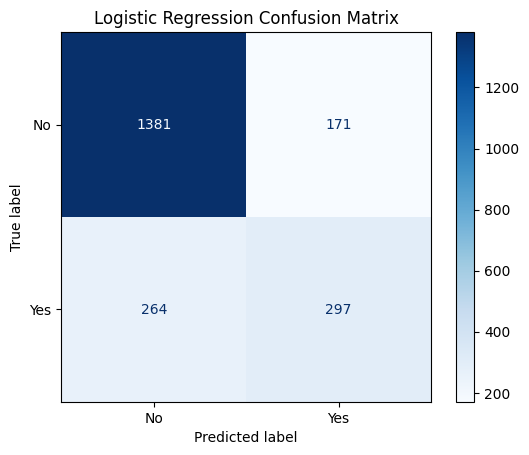

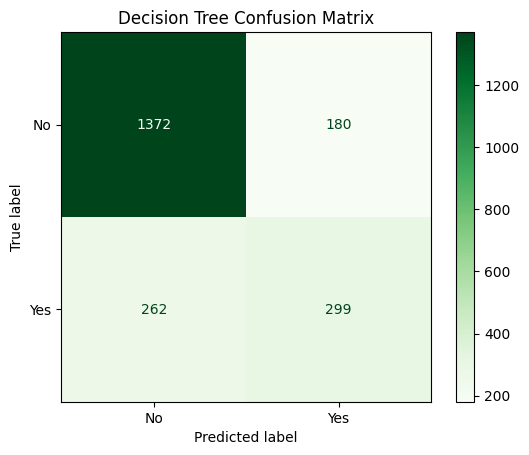

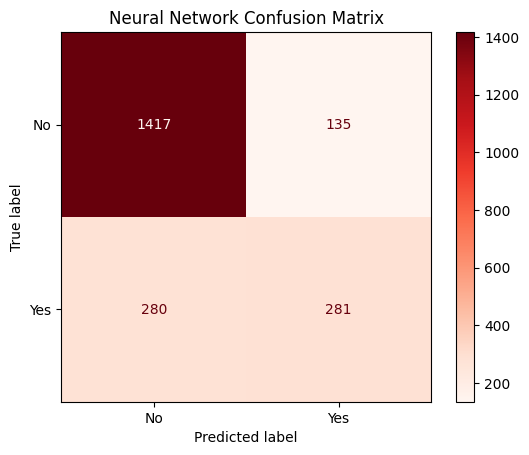

Logistic Regression Accuracy: 0.7941315664931378
Decision Tree Accuracy: 0.7908187411263606
Neural Network Accuracy: 0.8035967818267865


In [122]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt


y_encoder = LabelEncoder()
y_train_le = y_encoder.fit_transform(y_train)
y_test_le = y_encoder.transform(y_test)

# Logistic Regression
cm_log = confusion_matrix(y_test_le, y_pred_log)
ConfusionMatrixDisplay(cm_log, display_labels=y_encoder.classes_).plot(cmap="Blues")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

# Decision Tree
cm_dt = confusion_matrix(y_test_le, y_pred_dt)
ConfusionMatrixDisplay(cm_dt, display_labels=y_encoder.classes_).plot(cmap="Greens")
plt.title("Decision Tree Confusion Matrix")
plt.show()

#Neural Network
cm_nn = confusion_matrix(y_test_le, y_pred_nn)
ConfusionMatrixDisplay(cm_nn, display_labels=y_encoder.classes_).plot(cmap="Reds")
plt.title("Neural Network Confusion Matrix")
plt.show()
# Accuracy comparison
print("Logistic Regression Accuracy:", accuracy_score(y_test_le, y_pred_log))
print("Decision Tree Accuracy:", accuracy_score(y_test_le, y_pred_dt))
print("Neural Network Accuracy:", accuracy_score(y_test_le, y_pred_nn))

In [123]:
from sklearn.metrics import classification_report

print("Logistic Regression:")
print(classification_report(y_test_le, y_pred_log, target_names=y_encoder.classes_.astype(str)))

print("Decision Tree:")
print(classification_report(y_test_le, y_pred_dt, target_names=y_encoder.classes_.astype(str)))
print("Neural Network")
print(classification_report(y_test_le, y_pred_nn, target_names=y_encoder.classes_.astype(str)))

Logistic Regression:
              precision    recall  f1-score   support

          No       0.84      0.89      0.86      1552
         Yes       0.63      0.53      0.58       561

    accuracy                           0.79      2113
   macro avg       0.74      0.71      0.72      2113
weighted avg       0.79      0.79      0.79      2113

Decision Tree:
              precision    recall  f1-score   support

          No       0.84      0.88      0.86      1552
         Yes       0.62      0.53      0.57       561

    accuracy                           0.79      2113
   macro avg       0.73      0.71      0.72      2113
weighted avg       0.78      0.79      0.79      2113

Neural Network
              precision    recall  f1-score   support

          No       0.84      0.91      0.87      1552
         Yes       0.68      0.50      0.58       561

    accuracy                           0.80      2113
   macro avg       0.76      0.71      0.72      2113
weighted avg       0.79

--- Finding the Optimal Number of Clusters ---


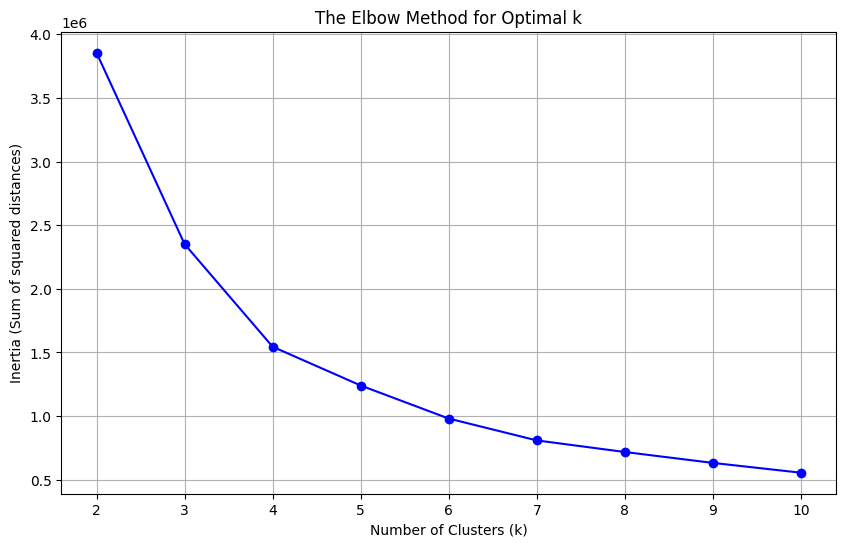


--- Applying K-Means with k=3 ---

--- Showcase 1: Churn Rate by Customer Cluster ---
         No Churn     Churn
Cluster                    
0        0.523474  0.476526
1        0.844156  0.155844
2        0.848161  0.151839


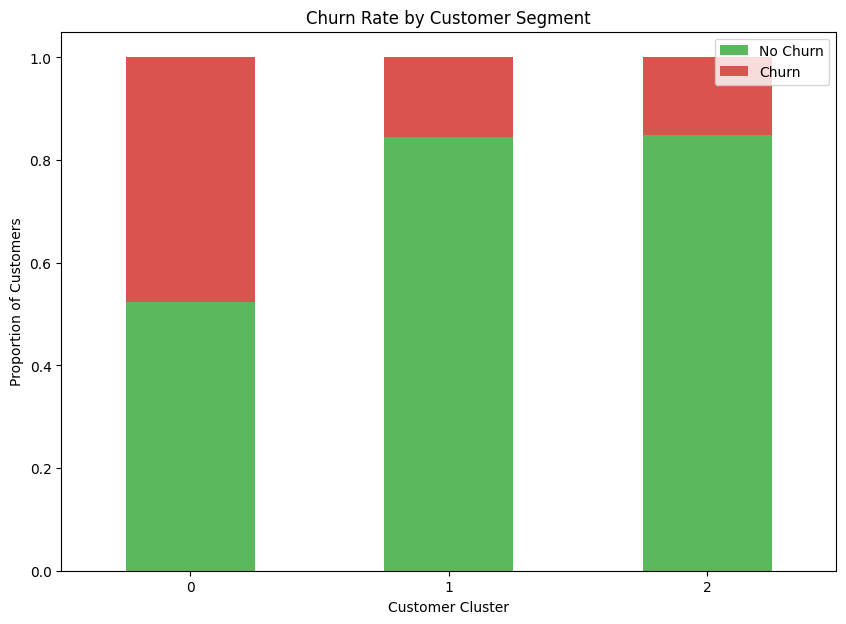


--- Showcase 2: Characteristics of Each Customer Cluster ---
         tenure  MonthlyCharges  TotalCharges
Cluster                                      
0         13.53           77.07          0.12
1         57.98           89.75          0.60
2         27.56           28.43          0.09


In [124]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


print("--- Finding the Optimal Number of Clusters ---")
inertia = []
k_range = range(2, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    kmeans.fit(X_train_le)
    inertia.append(kmeans.inertia_)


plt.figure(figsize=(10, 6))
plt.plot(k_range, inertia, 'bo-')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia (Sum of squared distances)')
plt.title('The Elbow Method for Optimal k')
plt.grid(True)
plt.show()


optimal_k = 3
print(f"\n--- Applying K-Means with k={optimal_k} ---")
kmeans = KMeans(n_clusters=optimal_k, n_init=10, random_state=42)

X_train_le['Cluster'] = kmeans.fit_predict(X_train_le)


analysis_df = X_train_le.copy()
analysis_df['Churn'] = y_train_le


print("\n--- Showcase 1: Churn Rate by Customer Cluster ---")
cluster_churn_rate = analysis_df.groupby('Cluster')['Churn'].value_counts(normalize=True).unstack().fillna(0)
cluster_churn_rate.columns = ['No Churn', 'Churn']
print(cluster_churn_rate)

cluster_churn_rate.plot(kind='bar', stacked=True, figsize=(10, 7),
                        color=['#5cb85c', '#d9534f'])
plt.title('Churn Rate by Customer Segment')
plt.ylabel('Proportion of Customers')
plt.xlabel('Customer Cluster')
plt.xticks(rotation=0)
plt.show()


print("\n--- Showcase 2: Characteristics of Each Customer Cluster ---")

cluster_characteristics = analysis_df.groupby('Cluster')[['tenure', 'MonthlyCharges', 'TotalCharges']].mean().round(2)
print(cluster_characteristics)